# Relate: A SQLite-Style Graph Database

Relate (formerly CypherLite) is an embedded graph database from Neo4j. It runs inside this Python process, stores a graph in one `.cl` file (or in memory) and is queried in Cypher.

In this notebook we'll load the London Underground data into it, ask three graph questions and move the results into pandas.

## 1. Install

The pinned versions below (pandas 3.1.1, pyarrow 26.0.1, matplotlib 3.11.2) need Python 3.11 or later. Relate itself runs on Python 3.9 and later.

In [1]:
%pip install matplotlib==3.11.2 \
             pandas==3.1.1 \
             pyarrow==26.0.1 \
             relate-db==1.0.0 --quiet

Note: you may need to restart the kernel to use updated packages.


## 2. Settings and helpers

In [2]:
import os
import pandas as pd
import pyarrow as pa
import relate
import time

from pathlib import Path
from relate import Database

In [3]:
DATA_DIR = Path("data")
DB_PATH = "tube.cl"          # one file; use ":memory:" for a throwaway database
RESET = True                 # delete the file first so the notebook can be re-run

def records(result):
    """Rows as a list of dicts. Uses .data when the result has it, otherwise reads the cursor."""
    if hasattr(result, "data"):
        data = result.data
        return data() if callable(data) else data
    return [dict(row) for row in result]

print("relate imported.")

relate imported.


## 3. Connect

If you've used `sqlite3`, this is the same shape: `connect()` gives us a handle, `execute()` runs a statement with named parameters.

In [4]:
if RESET and DB_PATH != ":memory:" and os.path.exists(DB_PATH):
    os.remove(DB_PATH)

db = relate.connect(DB_PATH)

db.execute("CREATE (:Station {name: $name})", {"name": "Test"})
print(records(db.execute("MATCH (s:Station) RETURN s.name AS name")))
db.execute("MATCH (s:Station {name: 'Test'}) DELETE s")
print("Connected.")

[{'name': 'Test'}]
Connected.


## 4. Load the London Underground data

The rows go in as a parameter and `UNWIND` turns the list into one row per record, much like `executemany` in SQLite. Each connection is stored once and matched in either direction later.

In [5]:
stations = pd.read_csv(DATA_DIR / "london_stations.csv")
links = pd.read_csv(DATA_DIR / "london_connections.csv")
lines_csv = pd.read_csv(DATA_DIR / "london_lines.csv")
for frame in (stations, links, lines_csv):
    frame.columns = frame.columns.str.strip()

# The connections file also holds other London rail lines. Keep the lines listed in the lines file,
# and only the stations those lines touch.
links = links[links["Tube Line"].str.strip().isin(set(lines_csv["Tube Line"].str.strip()))]
used = set(links["From Station"].str.strip()) | set(links["To Station"].str.strip())
stations = stations[stations["Station"].str.strip().isin(used)]

db.execute(
    "UNWIND $rows AS r "
    "MERGE (s:Station {name: r.name}) "
    "SET s.lat = r.lat, s.lon = r.lon",
    {"rows": [
        {"name": str(r["Station"]).strip(), "lat": float(r["Latitude"]), "lon": float(r["Longitude"])}
        for r in stations.to_dict("records")
    ]},
)

db.execute(
    "UNWIND $rows AS r "
    "MATCH (a:Station {name: r.a}), (b:Station {name: r.b}) "
    "CREATE (a)-[:CONNECTS_TO {line: r.line}]->(b)",
    {"rows": [
        {"a": str(r["From Station"]).strip(), "b": str(r["To Station"]).strip(), "line": str(r["Tube Line"]).strip()}
        for r in links.to_dict("records")
    ]},
)

print("Loaded.")

Loaded.


In [6]:
n_stations = records(db.execute("MATCH (s:Station) RETURN count(s) AS n"))[0]["n"]
n_links = records(db.execute("MATCH ()-[r:CONNECTS_TO]->() RETURN count(r) AS n"))[0]["n"]
print(f"{n_stations} stations, {n_links} connections ({len(links)} connection rows kept)")

349 stations, 458 connections (458 connection rows kept)


## 5. Ask graph questions

### 5.1 What is within three stops of Kennington?
A variable-length pattern follows connections up to a limit, in either direction.

In [7]:
nearby = records(db.execute(
    "MATCH p = (a:Station {name: $name})-[:CONNECTS_TO*1..3]-(b:Station) "
    "WHERE a <> b "
    "RETURN b.name AS station, min(length(p)) AS stops "
    "ORDER BY stops, station",
    {"name": "Kennington"},
))

pd.DataFrame(nearby)

,station,stops
0,Elephant and Castle,1
1,Nine Elms,1
2,Oval,1
3,Waterloo,1
4,Bank,2
5,Battersea Power Station,2
6,Borough,2
7,Embankment,2
8,Lambeth North,2
9,Southwark,2


### 5.2 Which stations are interchanges?
Group each station's connections by line and keep the ones served by more than one.

In [8]:
hubs = records(db.execute(
    "MATCH (s:Station)-[r:CONNECTS_TO]-() "
    "WITH s, collect(DISTINCT r.line) AS lines "
    "WHERE size(lines) > 1 "
    "RETURN s.name AS station, size(lines) AS lines, lines AS served_by "
    "ORDER BY lines DESC, station LIMIT 10"
))

hubs_df = pd.DataFrame(hubs)
hubs_df

,station,lines,served_by
0,Kings Cross St. Pancras,6,"[Victoria, Piccadilly, Northern, Metropolitan,..."
1,Baker Street,5,"[Metropolitan, Jubilee, Hammersmith and City, ..."
2,Bank,4,"[Northern, Central, Waterloo and City, DLR]"
3,Embankment,4,"[Northern, District, Circle, Bakerloo]"
4,Liverpool Street,4,"[Metropolitan, Hammersmith and City, Circle, C..."
5,Moorgate,4,"[Northern, Metropolitan, Hammersmith and City,..."
6,Paddington,4,"[Hammersmith and City, District, Circle, Baker..."
7,Waterloo,4,"[Waterloo and City, Northern, Jubilee, Bakerloo]"
8,West Ham,4,"[Jubilee, Hammersmith and City, DLR, District]"
9,Barbican,3,"[Metropolitan, Hammersmith and City, Circle]"


Text(0, 0.5, '')

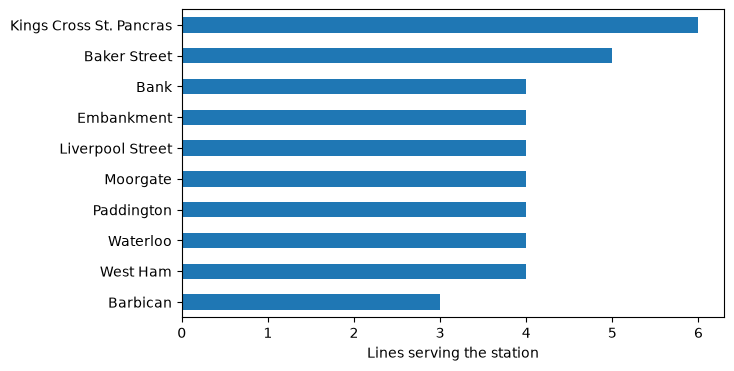

In [9]:
ax = hubs_df.plot.barh(x="station", y="lines", legend=False, figsize=(7, 4))
ax.invert_yaxis()
ax.set_xlabel("Lines serving the station")
ax.set_ylabel("")

### 5.3 How do I get from Kennington to Euston?
Cypher 25 path selectors ask for the shortest paths directly. Two details matter:

- **Bound the search.** An open-ended pattern such as `-+` or `*` makes the engine consider every path through a network full of loops and it will not finish. Cap the hops; the shortest route here is 8.
- **Name the line if you want one.** Restricting to the Northern Line gives the two branches. Where several lines serve the same stations, the graph holds parallel connections and each counts as a separate path.

In [10]:
ORIGIN, DEST, LINE = "Kennington", "Euston", "Northern"
MAX_HOPS = 10  # the shortest route is 8 hops; the bound keeps the search small

QUERIES = {
    "SHORTEST 3": (
        f"MATCH p = SHORTEST 3 (a:Station {{name: $origin}})-[:CONNECTS_TO {{line: $line}}]-{{1,{MAX_HOPS}}}(b:Station {{name: $dest}}) "
        "RETURN [n IN nodes(p) | n.name] AS stations, length(p) AS stops ORDER BY stops"
    ),
    "shortestPath": (
        f"MATCH p = shortestPath((a:Station {{name: $origin}})-[:CONNECTS_TO*1..{MAX_HOPS} {{line: $line}}]-(b:Station {{name: $dest}})) "
        "RETURN [n IN nodes(p) | n.name] AS stations, length(p) AS stops"
    ),
}

for name, query in QUERIES.items():
    t0 = time.perf_counter()
    try:
        found = records(db.execute(query, {"origin": ORIGIN, "dest": DEST, "line": LINE}))
        print(f"{name}: {len(found)} path(s) in {time.perf_counter() - t0:.2f}s")
        break
    except Exception as exc:
        print(f"{name} failed after {time.perf_counter() - t0:.2f}s: {type(exc).__name__}: {str(exc)[:120]}")

# Parallel connections can repeat a station sequence, so keep each sequence once.
routes = list({tuple(r["stations"]): r for r in found}.values())
for r in routes:
    print(f"{r['stops']} stops: {' > '.join(r['stations'])}")

SHORTEST 3: 2 path(s) in 0.00s
8 stops: Kennington > Waterloo > Embankment > Charing Cross > Leicester Square > Tottenham Court Road > Goodge Street > Warren Street > Euston
9 stops: Kennington > Elephant and Castle > Borough > London Bridge > Bank > Moorgate > Old Street > Angel > Kings Cross St. Pancras > Euston


### 5.4 And on the whole network?
Drop the line filter and ask for more paths than you need, then keep the distinct station sequences. Each route also reports the lines it uses, so we can see where it changes.

In [11]:
WHOLE_QUERY = (
    f"MATCH p = SHORTEST 20 (a:Station {{name: $origin}})-[:CONNECTS_TO]-{{1,{MAX_HOPS}}}(b:Station {{name: $dest}}) "
    "RETURN [n IN nodes(p) | n.name] AS stations, [r IN relationships(p) | r.line] AS lines, length(p) AS stops "
    "ORDER BY stops"
)

t0 = time.perf_counter()
whole = records(db.execute(WHOLE_QUERY, {"origin": ORIGIN, "dest": DEST}))
print(f"{len(whole)} paths in {time.perf_counter() - t0:.2f}s")

distinct = list({tuple(r["stations"]): r for r in whole}.values())[:3]
for r in distinct:
    print(f"{r['stops']} stops, lines {sorted(set(r['lines']))}: {' > '.join(r['stations'])}")

20 paths in 0.25s
6 stops, lines ['Jubilee', 'Northern', 'Victoria']: Kennington > Waterloo > Westminster > Green Park > Oxford Circus > Warren Street > Euston
7 stops, lines ['Circle', 'Metropolitan', 'Northern', 'Waterloo and City']: Kennington > Waterloo > Bank > Moorgate > Barbican > Farringdon > Kings Cross St. Pancras > Euston


## 6. Move results into pandas

Results come back as dictionaries, which pandas takes directly. For larger results the native `Database` class returns Arrow IPC bytes. That needs the file to be free, so close this connection first.

In [12]:
db.close()

adb = Database(DB_PATH)
buf = adb.execute_arrow("MATCH (s:Station) RETURN s.name AS name, s.lat AS lat, s.lon AS lon")
stations_df = pa.ipc.open_stream(buf).read_all().to_pandas()
print(stations_df.shape)
stations_df.head()

(349, 3)


,name,lat,lon
0,Abbey Road,51.531952,0.003723
1,Acton Town,51.503071,-0.280303
2,Addington Village,51.356239,-0.032665
3,Addiscombe,51.379808,-0.073213
4,Aldgate,51.514342,-0.075627


## 7. Keep it in one file

A path ending in `.cl` stores the log, snapshots and catalog in a single file. Reopen it and the graph is still there. Close a connection before another one opens the same file: Relate allows one writer and a second opener of a locked database gets an error.

In [13]:
try:
    adb.close()
except AttributeError:
    pass

db = relate.connect(DB_PATH)
print(records(db.execute("MATCH (s:Station) RETURN count(s) AS stations")))
print(f"File size: {os.path.getsize(DB_PATH) / 1024:.0f} KB" if os.path.exists(DB_PATH) else "No file (in-memory).")

[{'stations': 349}]
File size: 204 KB


In [14]:
db.close()
print("Closed.")

Closed.
